# How accurate are the estimates?

This notebook measures how well `house_price_estimate` values homes in England, and where it does badly, so you can decide how far to trust an estimate for a given kind of property.

**Test.** We take a random sample of sales registered with HM Land Registry between **August 2025 and July 2026**, the latest 12 months covered by the House Price Index. Each home is valued *as of its sale date*, using only sales, index values and EPCs from before that date, and the estimate is compared with the price actually paid. The address is rebuilt from the Land Registry record and goes through the normal parsing and matching, so address matching is tested too. New builds are excluded, because they have no sale history and are priced by developers.

The `low`–`high` ranges were calibrated on 2024 sales, so the coverage figures here are out of sample.

**Caveats.**
- HPI figures are as published now, and recent months are revised after publication. This is a small look-ahead that slightly flatters the results.
- Land Registry registrations lag by a few months. Slow-registering sales, often leasehold flats and probate sales, are under-represented in the most recent months.
- A sale price is itself a noisy measure of value. A perfect model would still show a few per cent error.

All outputs below are aggregates. No addresses or postcodes are displayed.

## Setup

Run the backtest once and cache the results in `data/processed/` (gitignored). That takes about 20 minutes. Set `RECOMPUTE = True` after a rebuild or recalibration. Everything runs inside `no_network()`.

In [1]:
from pathlib import Path
import logging
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path.cwd().parent))
from house_price_estimate.backtest import run_backtest, sample_sales
from house_price_estimate.config import DEFAULT_DATA_DIR, ModelParams, Paths
from house_price_estimate.estimate import Estimator
from house_price_estimate.offline import no_network

logging.getLogger("house_price_estimate").setLevel(logging.WARNING)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

PATHS = Paths(DEFAULT_DATA_DIR)
START, END = "2025-08-01", "2026-08-01"   # sales Aug 2025 - Jul 2026
N_ENGLAND, N_EAST, SEED = 20_000, 6_000, 2026
NORFOLK, SUFFOLK = "E10000020", "E10000029"
RECOMPUTE = False

In [2]:
KEEP_NO_EPC = ["estimate", "low", "high", "method", "calibration_group", "confidence"]


def geography(est, postcodes):
    """Local lookup of region, county, district and rural-urban class."""
    return est.conn.execute(
        "SELECT postcode, rgn, cty, lad, ruc21 FROM onspd WHERE postcode IN (SELECT unnest(?))",
        [sorted(set(postcodes.dropna()))],
    ).df()


def backtest(name, **sample_kw):
    cache = PATHS.processed / f"notebook_backtest_{name}.parquet"
    if cache.exists() and not RECOMPUTE:
        return pd.read_parquet(cache)
    with no_network():
        est = Estimator(PATHS.db)
        est_no_epc = Estimator(PATHS.db, ModelParams(use_epc=False))
        sales = sample_sales(est, None, sample_kw.pop("n"), SEED, start=START, end=END, **sample_kw)
        df = run_backtest(est, None, 0, sales=sales)
        no_epc = run_backtest(est_no_epc, None, 0, sales=sales)
        df = df.join(no_epc[KEEP_NO_EPC].add_prefix("noepc_"))
        df = df.merge(geography(est, df["postcode"]), on="postcode", how="left")
        est.close(); est_no_epc.close()
    df["years_since_last_sale"] = (
        (pd.to_datetime(df["sale_date"]) - pd.to_datetime(df["last_sale_date"])).dt.days / 365.25)
    df = df.drop(columns=["postcode"])  # nothing identifying is kept or shown
    df.to_parquet(cache)
    return df


eng = backtest("england", n=N_ENGLAND, england_only=True)
east = backtest("norfolk_suffolk", n=N_EAST, counties=[NORFOLK, SUFFOLK])
print(f"England sample: {len(eng):,} sales, {eng['estimate'].notna().mean():.1%} estimated")
print(f"Norfolk & Suffolk sample: {len(east):,} sales, {east['estimate'].notna().mean():.1%} estimated")
print(f"Sale dates {eng['sale_date'].min():%b %Y} to {eng['sale_date'].max():%b %Y}")

England sample: 20,000 sales, 100.0% estimated
Norfolk & Suffolk sample: 6,000 sales, 100.0% estimated
Sale dates Aug 2025 to Jul 2026


In [3]:
REGIONS = {"E12000001": "North East", "E12000002": "North West", "E12000003": "Yorkshire & Humber",
           "E12000004": "East Midlands", "E12000005": "West Midlands", "E12000006": "East of England",
           "E12000007": "London", "E12000008": "South East", "E12000009": "South West"}
RUC = {"UN1": "Urban, nearer a major town/city", "UF1": "Urban, further from one",
       "RLN1": "Larger rural, nearer", "RLF1": "Larger rural, further",
       "RSN1": "Smaller rural, nearer", "RSF1": "Smaller rural, further"}
DISTRICTS = {"E07000148": "Norwich", "E07000144": "Broadland", "E07000149": "South Norfolk",
             "E07000143": "Breckland", "E07000145": "Great Yarmouth",
             "E07000146": "King's Lynn & W Norfolk", "E07000147": "North Norfolk",
             "E07000202": "Ipswich", "E07000200": "Babergh", "E07000203": "Mid Suffolk",
             "E07000244": "East Suffolk", "E07000245": "West Suffolk"}
GROUPS = {"repeat_le5y": "Earlier sale ≤5 years before", "repeat_5_15y": "Earlier sale 5–15 years before",
          "repeat_gt15y": "Earlier sale >15 years before", "repeat_only": "Earlier sale, no comparables",
          "comps_floor_area": "No earlier sale: comparables + floor area",
          "comps_no_floor_area": "No earlier sale: comparables, no floor area"}
TYPES = {"D": "Detached", "S": "Semi-detached", "T": "Terraced", "F": "Flat/maisonette"}


def label(df):
    df = df.copy()
    df["region"] = df["rgn"].map(REGIONS)
    df["ruc"] = df["ruc21"].map(RUC)
    df["urban_rural"] = np.where(df["ruc21"].str.startswith("U"), "Urban",
                                 np.where(df["ruc21"].str.startswith("R"), "Rural", None))
    df["district"] = df["lad"].map(DISTRICTS)
    df["group"] = df["calibration_group"].map(GROUPS)
    df["type"] = df["actual_type"].map(TYPES)
    df["county"] = df["cty"].map({NORFOLK: "Norfolk", SUFFOLK: "Suffolk"})
    return df


eng, east = label(eng), label(east)

## How to read the figures

Most figures have three panels, with one bar per subset. The label gives the number of sales `n`.

1. **Median absolute error.** Half of estimates are closer to the sale price than this. The whiskers are bootstrap 95% confidence intervals, and the dashed line is the figure for the whole England sample.
2. **Bias.** The median of (estimate − price) / price. A positive bias means the subset tends to be over-valued.
3. **Range coverage.** The share of sale prices that fall inside `low`–`high`. The range is meant to be an 80% interval (red line). If coverage is well below 80%, the range is too optimistic for that subset.

Faded bars have fewer than 100 sales and should be treated as indicative only. A table under each figure gives the same numbers, plus the share within ±20%.

In [4]:
RNG = np.random.default_rng(0)


def boot_ci(x, reps=400):
    x = np.asarray(x)
    if len(x) < 2:
        return (np.nan, np.nan)
    m = np.median(x[RNG.integers(0, len(x), (reps, len(x)))], axis=1)
    return tuple(np.percentile(m, [2.5, 97.5]))


def stats(g, prefix=""):
    g = g.dropna(subset=[prefix + "estimate"])
    e = (g[prefix + "estimate"] / g["actual"] - 1).to_numpy()
    a = np.abs(e)
    cov = ((g["actual"] >= g[prefix + "low"]) & (g["actual"] <= g[prefix + "high"])).to_numpy()
    return dict(n=len(g), median_error=np.median(a) if len(a) else np.nan, err_ci=boot_ci(a),
                within_10=(a <= 0.10).mean(), within_20=(a <= 0.20).mean(),
                bias=np.median(e) if len(e) else np.nan, bias_ci=boot_ci(e),
                coverage=cov.mean(), cov_se=np.sqrt(cov.mean() * (1 - cov.mean()) / max(len(g), 1)))


def table(t):
    out = t[["n", "median_error", "within_10", "within_20", "bias", "coverage"]].copy()
    for c in ["median_error", "within_10", "within_20", "bias", "coverage"]:
        out[c] = out[c].map(lambda v: f"{v:+.1%}" if c == "bias" else f"{v:.1%}")
    out["n"] = out["n"].map("{:,}".format)
    return out.rename(columns={"median_error": "median error", "within_10": "within ±10%",
                               "within_20": "within ±20%", "coverage": "in range"})


REF = stats(eng)["median_error"]


def subset_plot(df, by, order=None, title="", min_n=100, prefix="", show_table=True):
    keys = order if order is not None else sorted(df[by].dropna().unique())
    keys = [k for k in keys if df.loc[df[by] == k, prefix + "estimate"].notna().any()]
    t = pd.DataFrame.from_dict({k: stats(df[df[by] == k], prefix) for k in keys}, orient="index")
    y = np.arange(len(t))[::-1]
    alpha = np.where(t["n"] >= min_n, 0.9, 0.35)
    fig, ax = plt.subplots(1, 3, figsize=(13, 0.42 * len(t) + 1.5), sharey=True)
    err = lambda col, ci: np.abs(np.array([list(c) for c in t[ci]]).T - t[col].to_numpy())
    for i, (col, ci, colour) in enumerate([("median_error", "err_ci", "#4477aa"), ("bias", "bias_ci", "#cc6677")]):
        ax[i].barh(y, t[col], xerr=err(col, ci), color=colour, edgecolor="none",
                   error_kw=dict(lw=1, capsize=2))
        for bar, a in zip(ax[i].patches, alpha):
            bar.set_alpha(a)
    ax[2].barh(y, t["coverage"], xerr=1.96 * t["cov_se"], color="#228833", error_kw=dict(lw=1, capsize=2))
    for bar, a in zip(ax[2].patches, alpha):
        bar.set_alpha(a)
    ax[0].axvline(REF, ls="--", c="k", lw=1)
    ax[1].axvline(0, c="k", lw=1)
    ax[2].axvline(0.8, ls="--", c="red", lw=1)
    ax[2].set_xlim(0.4, 1)
    ax[0].set_yticks(y, [f"{k}  (n={n:,})" for k, n in zip(t.index, t["n"])])
    for a, name in zip(ax, ["median absolute error", "bias (median signed error)", "price inside 80% range"]):
        a.set_title(name, fontsize=10)
        a.xaxis.set_major_locator(MaxNLocator(5))
        a.xaxis.set_major_formatter(PercentFormatter(1))
        a.grid(axis="y", visible=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, weight="bold")
    fig.tight_layout()
    plt.show()
    if show_table:
        display(table(t))
    return t

## 1. Overall

,n,median error,within ±10%,within ±20%,bias,in range
with EPC,"20,000",8.9%,54.6%,79.9%,+1.0%,81.1%
without EPC,"20,000",10.7%,47.7%,73.6%,+0.5%,80.6%


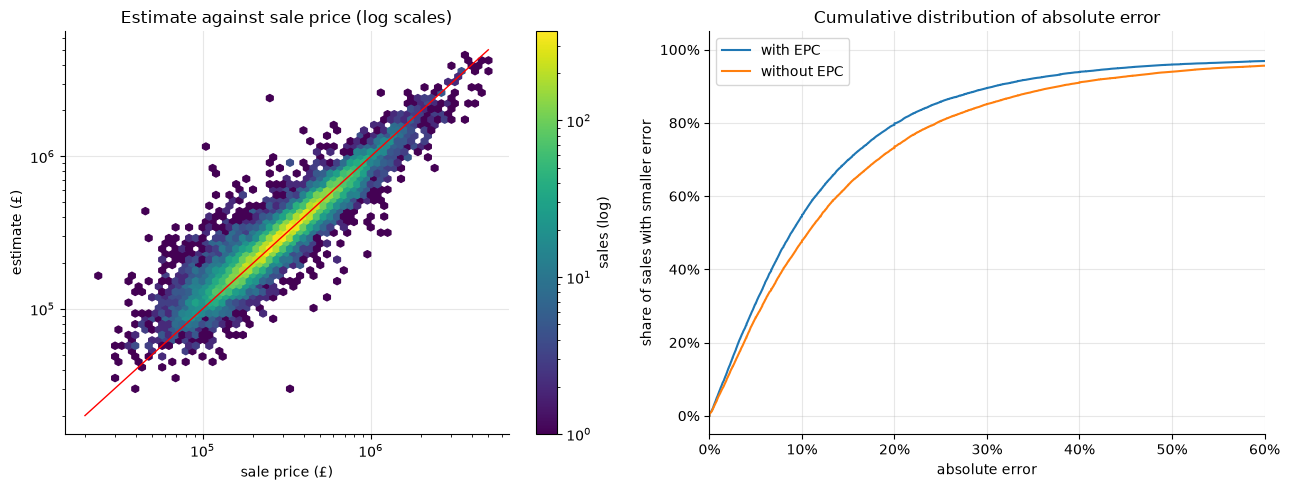

In [5]:
overall = pd.DataFrame({"with EPC": stats(eng), "without EPC": stats(eng, "noepc_")}).T
display(table(overall))

ok = eng.dropna(subset=["estimate"])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
hb = ax[0].hexbin(ok["actual"], ok["estimate"], xscale="log", yscale="log", gridsize=60,
                  bins="log", cmap="viridis", mincnt=1, extent=(4.3, 6.7, 4.3, 6.7))
ax[0].plot([2e4, 5e6], [2e4, 5e6], c="red", lw=1)
ax[0].set(xlabel="sale price (£)", ylabel="estimate (£)", title="Estimate against sale price (log scales)")
fig.colorbar(hb, ax=ax[0], label="sales (log)")
for prefix, name in [("", "with EPC"), ("noepc_", "without EPC")]:
    a = np.sort(np.abs(eng[prefix + "estimate"] / eng["actual"] - 1).dropna())
    ax[1].plot(a, np.arange(1, len(a) + 1) / len(a), label=name)
ax[1].set(xlim=(0, 0.6), xlabel="absolute error", ylabel="share of sales with smaller error",
          title="Cumulative distribution of absolute error")
ax[1].xaxis.set_major_formatter(PercentFormatter(1))
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].legend()
fig.tight_layout()
plt.show()

## 2. What evidence was available

**Why this subset.** The method has two sources of evidence. One is the home's *own* previous sale, indexed to today. The other is *comparable* nearby sales, scaled by floor area when an EPC gives one. Which of these exists is the biggest single driver of accuracy, and you can see it in the output (`calibration_group`, `method`). The calibrated ranges are also set separately for each of these groups.

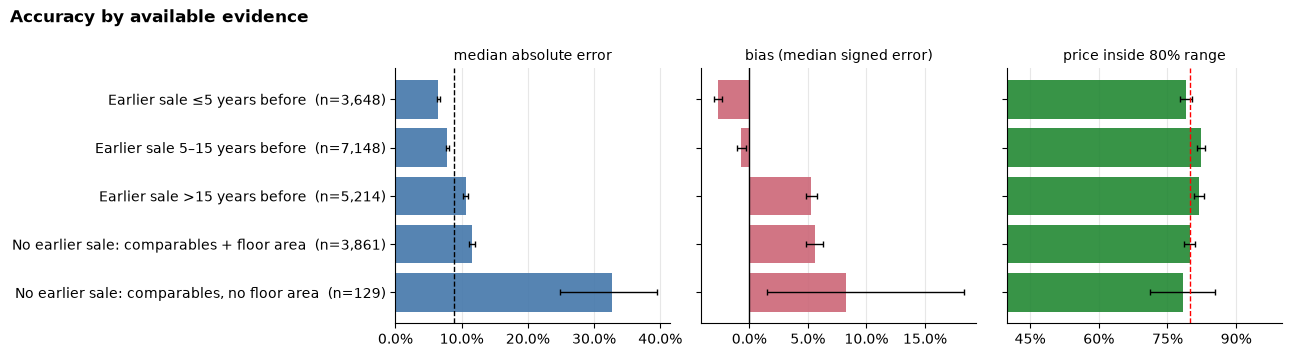

,n,median error,within ±10%,within ±20%,bias,in range
Earlier sale ≤5 years before,"3,648",6.5%,67.1%,87.0%,-2.7%,79.0%
Earlier sale 5–15 years before,"7,148",7.8%,59.7%,85.4%,-0.7%,82.3%
Earlier sale >15 years before,"5,214",10.6%,47.8%,75.6%,+5.3%,81.8%
No earlier sale: comparables + floor area,"3,861",11.6%,43.9%,70.4%,+5.6%,79.8%
"No earlier sale: comparables, no floor area",129,32.7%,20.2%,33.3%,+8.2%,78.3%


In [6]:
t_group = subset_plot(eng, "group", list(GROUPS.values()), "Accuracy by available evidence")

## 3. Confidence label

**Why this subset.** `confidence` is the label most users will filter on. It should sort estimates into clearly different error levels, and the range should still cover about 80% at each level.

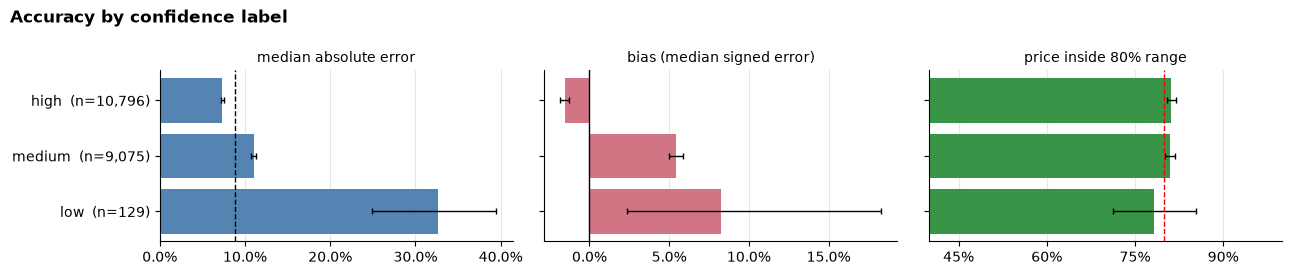

,n,median error,within ±10%,within ±20%,bias,in range
high,"10,796",7.3%,62.2%,85.9%,-1.6%,81.2%
medium,"9,075",11.0%,46.1%,73.4%,+5.4%,81.0%
low,129,32.7%,20.2%,33.3%,+8.2%,78.3%


confidence     high medium low
share of sales  54%    45%  1%


In [7]:
t_conf = subset_plot(eng, "confidence", ["high", "medium", "low"], "Accuracy by confidence label")
print((eng["confidence"].value_counts(normalize=True).reindex(["high", "medium", "low"])
       .map("{:.0%}".format).rename("share of sales").to_frame().T.to_string()))

## 4. Property type

**Why this subset.** Types differ in how similar a home is to its neighbours. Terraced and semi-detached streets are fairly uniform. Detached houses vary much more in size and plot. Flats vary by floor, outlook, lease length and service charge, and none of these is in the data.

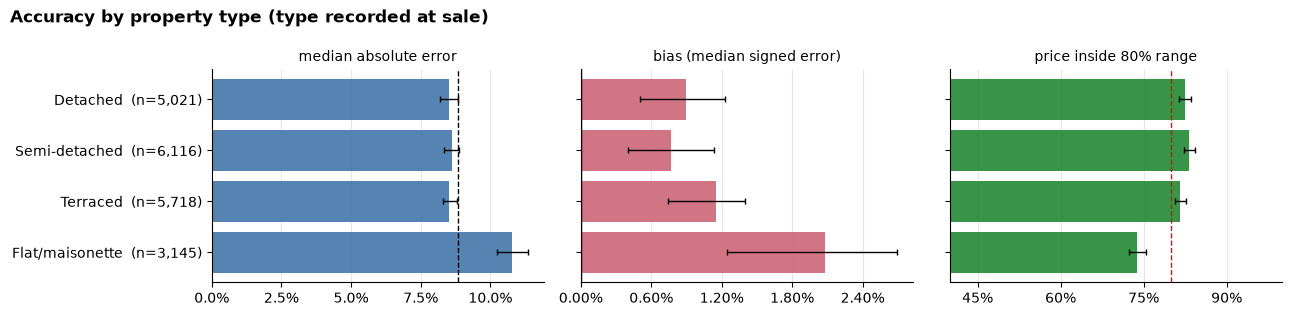

,n,median error,within ±10%,within ±20%,bias,in range
Detached,"5,021",8.5%,55.9%,81.4%,+0.9%,82.4%
Semi-detached,"6,116",8.6%,56.3%,82.3%,+0.8%,83.3%
Terraced,"5,718",8.5%,55.9%,80.1%,+1.2%,81.6%
Flat/maisonette,"3,145",10.8%,47.1%,72.5%,+2.1%,73.8%


In [8]:
t_type = subset_plot(eng, "type", list(TYPES.values()), "Accuracy by property type (type recorded at sale)")

## 5. Region

**Why this subset.** Markets move at different speeds, and the House Price Index is applied at local-authority level. London has many flats, a lot of variation within short distances, and recent price falls in parts of inner London, so it may behave differently from the rest of England.

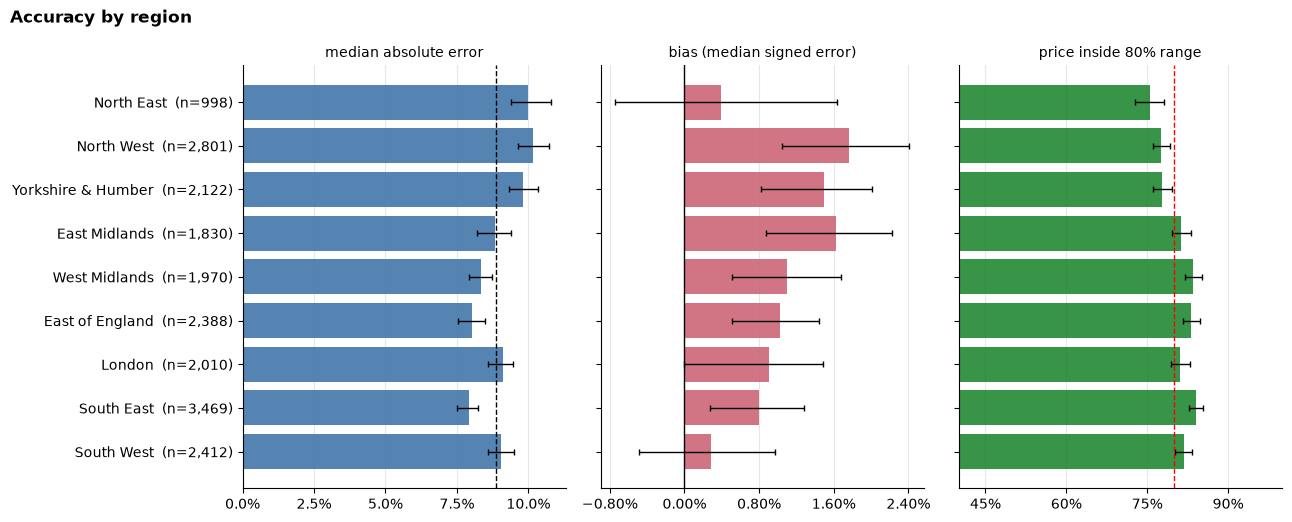

,n,median error,within ±10%,within ±20%,bias,in range
North East,998,10.0%,49.8%,74.2%,+0.4%,75.5%
North West,"2,801",10.2%,49.6%,76.0%,+1.8%,77.6%
Yorkshire & Humber,"2,122",9.8%,50.7%,76.5%,+1.5%,77.8%
East Midlands,"1,830",8.8%,54.5%,81.2%,+1.6%,81.3%
West Midlands,"1,970",8.3%,56.9%,81.5%,+1.1%,83.6%
East of England,"2,388",8.0%,58.6%,82.7%,+1.0%,83.2%
London,"2,010",9.1%,54.1%,79.4%,+0.9%,81.1%
South East,"3,469",7.9%,58.8%,82.8%,+0.8%,84.1%
South West,"2,412",9.0%,54.7%,80.8%,+0.3%,81.8%


In [9]:
t_region = subset_plot(eng, "region", list(REGIONS.values()), "Accuracy by region")

## 6. Value band

**Why this subset.** Automated valuations tend to under-value the most expensive homes and over-value the cheapest. Unusual features, such as land, views or very poor condition, are concentrated at the extremes.

**Why bands of the *estimate*, not of the sale price.** Grouping by sale price would select homes that sold *above* their typical value into the top band, and homes that sold *below* it into the bottom band. Even an unbiased model would then look as if it under-valued expensive homes. This is regression to the mean. The left panel below shows the artefact. A user only knows the estimate, so we band by that.

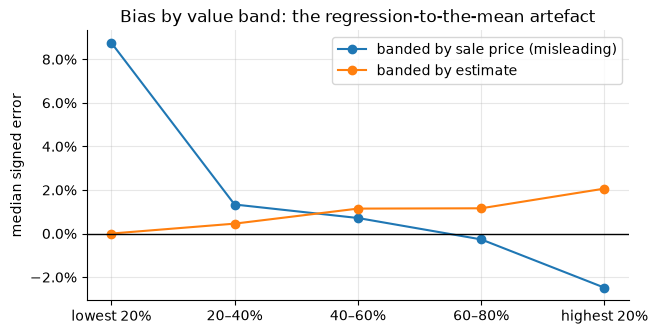

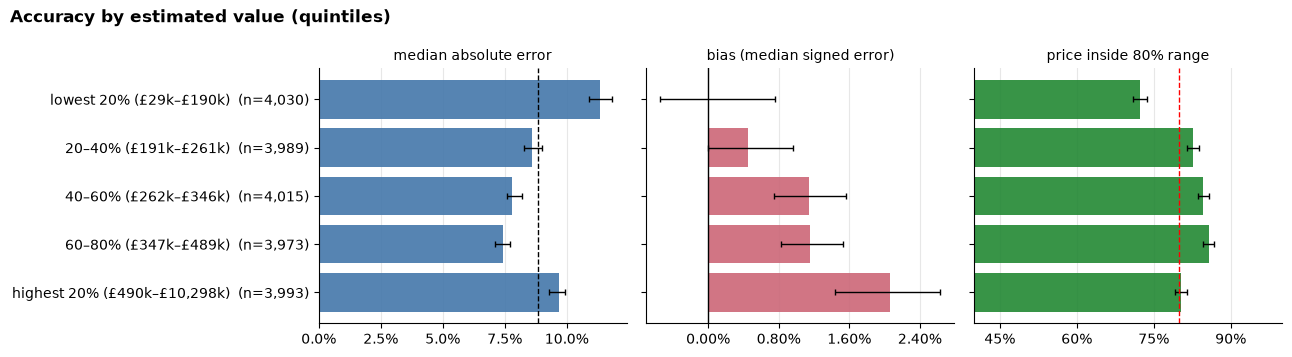

,n,median error,within ±10%,within ±20%,bias,in range
lowest 20% (£29k–£190k),"4,030",11.3%,45.1%,71.5%,+0.0%,72.3%
20–40% (£191k–£261k),"3,989",8.6%,55.2%,81.0%,+0.5%,82.6%
40–60% (£262k–£346k),"4,015",7.8%,60.2%,83.8%,+1.1%,84.7%
60–80% (£347k–£489k),"3,973",7.4%,61.3%,84.1%,+1.2%,85.7%
"highest 20% (£490k–£10,298k)","3,993",9.7%,51.5%,79.0%,+2.1%,80.3%


In [10]:
ok = eng.dropna(subset=["estimate"]).copy()
q_labels = ["lowest 20%", "20–40%", "40–60%", "60–80%", "highest 20%"]
ok["est_band"] = pd.qcut(ok["estimate"], 5, labels=q_labels)
ok["act_band"] = pd.qcut(ok["actual"], 5, labels=q_labels)
fig, ax = plt.subplots(figsize=(7, 3.5))
for band, name in [("act_band", "banded by sale price (misleading)"), ("est_band", "banded by estimate")]:
    b = ok.groupby(band, observed=True)["error"].median()
    ax.plot(q_labels, b.values, marker="o", label=name)
ax.axhline(0, c="k", lw=1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(ylabel="median signed error", title="Bias by value band: the regression-to-the-mean artefact")
ax.legend()
plt.show()

edges = ok.groupby("est_band", observed=True)["estimate"].agg(["min", "max"])
order = [f"{q} (£{lo/1e3:,.0f}k–£{hi/1e3:,.0f}k)" for q, (lo, hi) in zip(q_labels, edges.values)]
ok["value_band"] = ok["est_band"].cat.rename_categories(order).astype(str)
t_value = subset_plot(ok, "value_band", order, "Accuracy by estimated value (quintiles)")

## 7. Rural and urban locations

**Why this subset.** Rural homes are harder to value for three reasons:
- they vary more (age, plot size, outbuildings, conversions);
- there are fewer comparable sales nearby, so comparables come from further away;
- they sell less often, so fewer of them have a recent sale of their own.

We use the ONS 2021 Rural Urban Classification of each postcode's output area. It has six classes: urban, larger rural settlements and smaller rural settlements, each split by whether the place is nearer to or further from a major town or city.

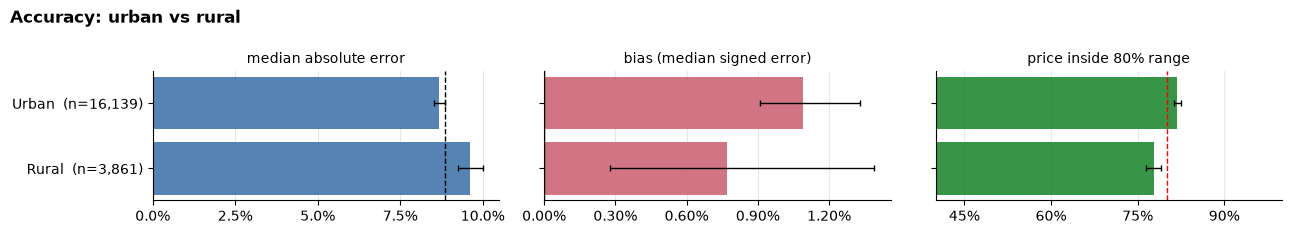

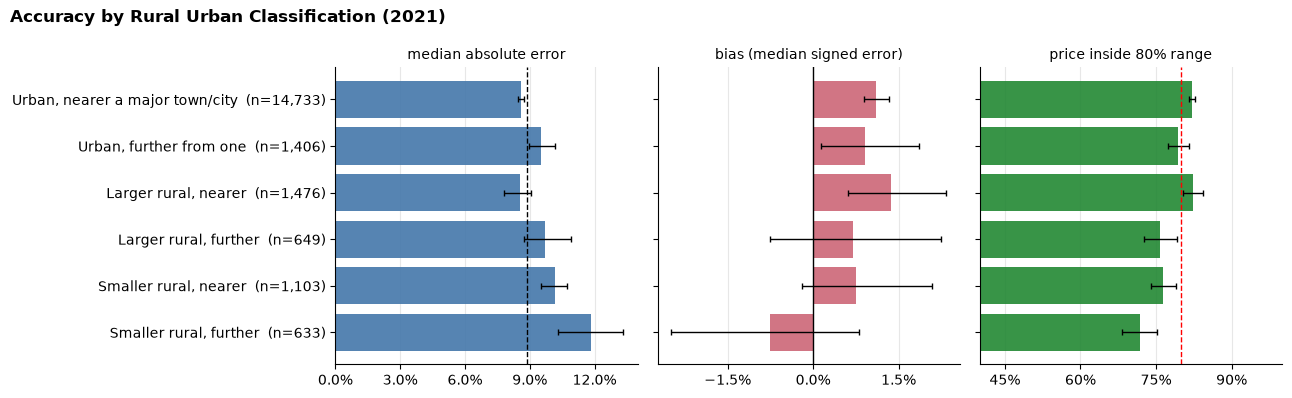

,n,median error,within ±10%,within ±20%,bias,in range
"Urban, nearer a major town/city","14,733",8.6%,55.7%,80.7%,+1.1%,82.1%
"Urban, further from one","1,406",9.5%,51.6%,79.9%,+0.9%,79.4%
"Larger rural, nearer","1,476",8.5%,56.8%,81.4%,+1.4%,82.3%
"Larger rural, further",649,9.7%,51.0%,75.3%,+0.7%,75.8%
"Smaller rural, nearer","1,103",10.2%,49.2%,75.8%,+0.7%,76.4%
"Smaller rural, further",633,11.8%,44.7%,69.8%,-0.7%,71.7%


In [11]:
t_ru = subset_plot(eng, "urban_rural", ["Urban", "Rural"], "Accuracy: urban vs rural", show_table=False)
t_ruc = subset_plot(eng, "ruc", list(RUC.values()), "Accuracy by Rural Urban Classification (2021)")

**Is rural harder in itself, or does it just have less evidence?** The first figure shows how far the comparables search had to reach and which evidence was available. The second compares urban and rural sales *with the same kind of evidence*. If rural error is still higher within each evidence group, the difficulty is intrinsic and not only a lack of data.

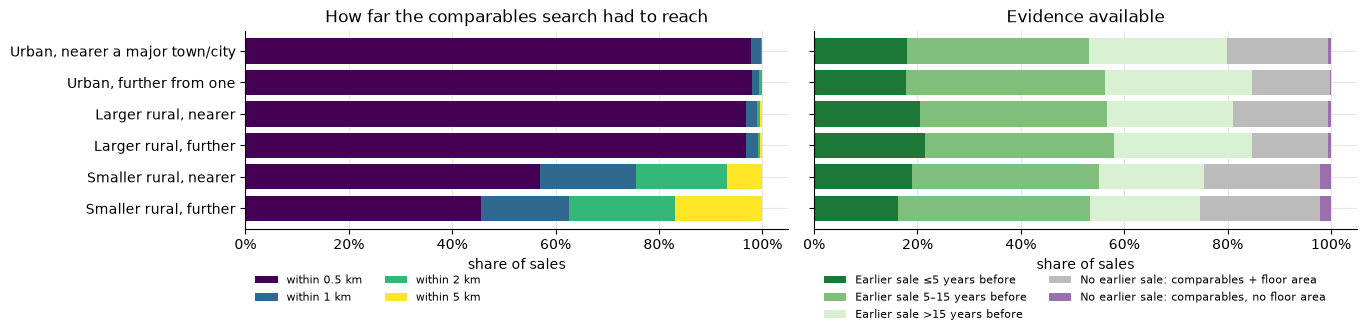

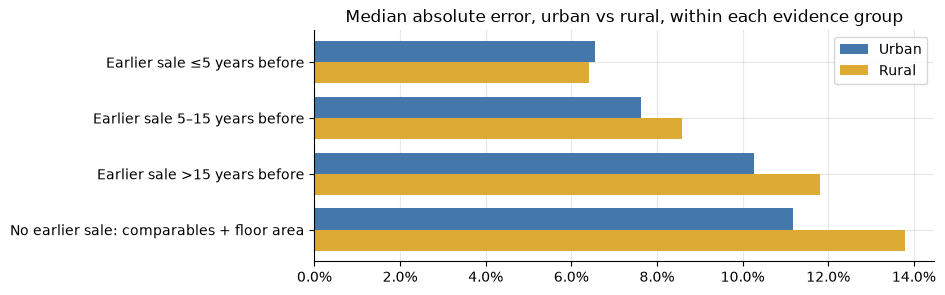

,Urban,Rural
Earlier sale ≤5 years before,"6.5% (n=2,896)",6.4% (n=752)
Earlier sale 5–15 years before,"7.6% (n=5,743)","8.6% (n=1,405)"
Earlier sale >15 years before,"10.3% (n=4,320)",11.8% (n=894)
No earlier sale: comparables + floor area,"11.2% (n=3,101)",13.8% (n=760)


In [12]:
order = list(RUC.values())
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
rad = pd.crosstab(eng["ruc"], eng["comps_radius_m"].fillna(-1).astype(int), normalize="index").reindex(order)
rad.columns = ["none found" if c < 0 else f"within {c/1000:g} km" for c in rad.columns]
rad.plot.barh(stacked=True, ax=ax[0], cmap="viridis", width=0.8)
ax[0].set(title="How far the comparables search had to reach", ylabel="")
grp = pd.crosstab(eng["ruc"], eng["group"], normalize="index").reindex(order)
grp = grp[[c for c in GROUPS.values() if c in grp.columns]]
grp.plot.barh(stacked=True, ax=ax[1], color=["#1b7837", "#7fbf7b", "#d9f0d3", "#bbbbbb", "#9970ab", "#762a83"][:grp.shape[1]], width=0.8)
ax[1].set(title="Evidence available", ylabel="")
ax[0].invert_yaxis()
for a in ax:
    a.set_xlabel("share of sales")
    a.xaxis.set_major_formatter(PercentFormatter(1))
    a.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

main = ["repeat_le5y", "repeat_5_15y", "repeat_gt15y", "comps_floor_area"]
within = (eng.dropna(subset=["estimate"]).assign(ape=lambda d: d["error"].abs())
          .groupby(["calibration_group", "urban_rural"])["ape"].agg(["median", "size"]).unstack().reindex(main))
fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(main))
for j, (ur, colour) in enumerate([("Urban", "#4477aa"), ("Rural", "#ddaa33")]):
    ax.barh(y + (j - 0.5) * 0.38, within[("median", ur)], height=0.38, color=colour, label=ur)
ax.set_yticks(y, [GROUPS[k] for k in main])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Median absolute error, urban vs rural, within each evidence group", xlabel="")
ax.legend()
plt.show()
out = pd.DataFrame({ur: [f"{m:.1%} (n={n:,})" for m, n in zip(within[("median", ur)], within[("size", ur)])]
                    for ur in ["Urban", "Rural"]}, index=[GROUPS[k] for k in main])
display(out)

## 8. Address matching and property type

**Why this subset.** The repeat-sale estimate depends on finding the home's own earlier sales. The address is matched within its postcode: `exact` (same house and flat numbers, in order), `fuzzy` (same identifiers in a different order, or a house name matched approximately) or `none`.
- `none` is mostly homes that really have not sold since 1995. It can also mean a missed match, for example when the address was written differently.
- A wrong property type (for example, a flat treated as a house) sends the comparables search to the wrong market. We compare the type the estimator used with the type recorded at the sale.

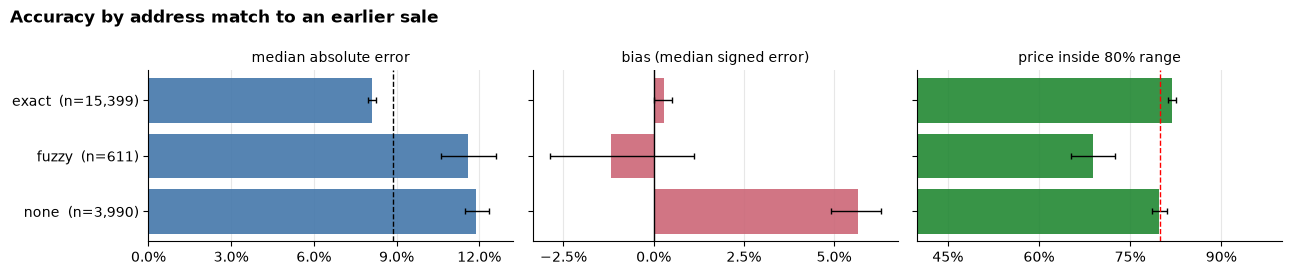

,n,median error,within ±10%,within ±20%,bias,in range
exact,"15,399",8.1%,58.1%,83.0%,+0.3%,81.9%
fuzzy,611,11.6%,43.2%,71.4%,-1.2%,68.9%
none,"3,990",11.9%,43.2%,69.2%,+5.7%,79.8%


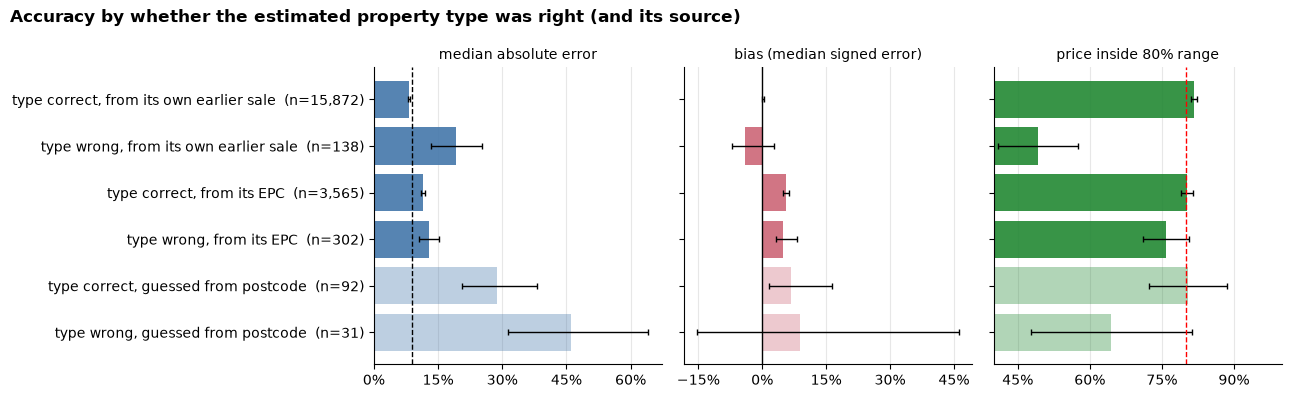

,n,median error,within ±10%,within ±20%,bias,in range
"type correct, from its own earlier sale","15,872",8.2%,57.7%,82.8%,+0.3%,81.7%
"type wrong, from its own earlier sale",138,19.1%,29.7%,52.9%,-4.1%,49.3%
"type correct, from its EPC","3,565",11.6%,44.1%,70.8%,+5.7%,80.3%
"type wrong, from its EPC",302,12.8%,41.7%,65.2%,+5.0%,75.8%
"type correct, guessed from postcode",92,28.9%,22.8%,38.0%,+6.7%,80.4%
"type wrong, guessed from postcode",31,46.2%,9.7%,19.4%,+8.9%,64.5%


In [13]:
t_match = subset_plot(eng, "ppd_match", ["exact", "fuzzy", "none"], "Accuracy by address match to an earlier sale")
eng["type_check"] = np.where(eng["property_type"] == eng["actual_type"], "type correct", "type wrong")
SOURCE = {"ppd": "from its own earlier sale", "epc": "from its EPC"}
eng["type_check"] = eng["type_check"] + ", " + eng["property_type_source"].map(SOURCE).fillna("guessed from postcode")
order = [f"type {a}, {b}" for b in list(SOURCE.values()) + ["guessed from postcode"] for a in ["correct", "wrong"]]
t_tcheck = subset_plot(eng, "type_check", order, "Accuracy by whether the estimated property type was right (and its source)")

## 9. Age of the earlier sale

**Why this subset.** An old sale price, even indexed, misses everything that has changed since: extensions, renovation or neglect, and changes in the area that the local-authority index does not capture. This shows how quickly the earlier sale loses value as evidence. The model's repeat-sale weight falls from 0.9 with the age of the sale, and the confidence label changes at 15 years.

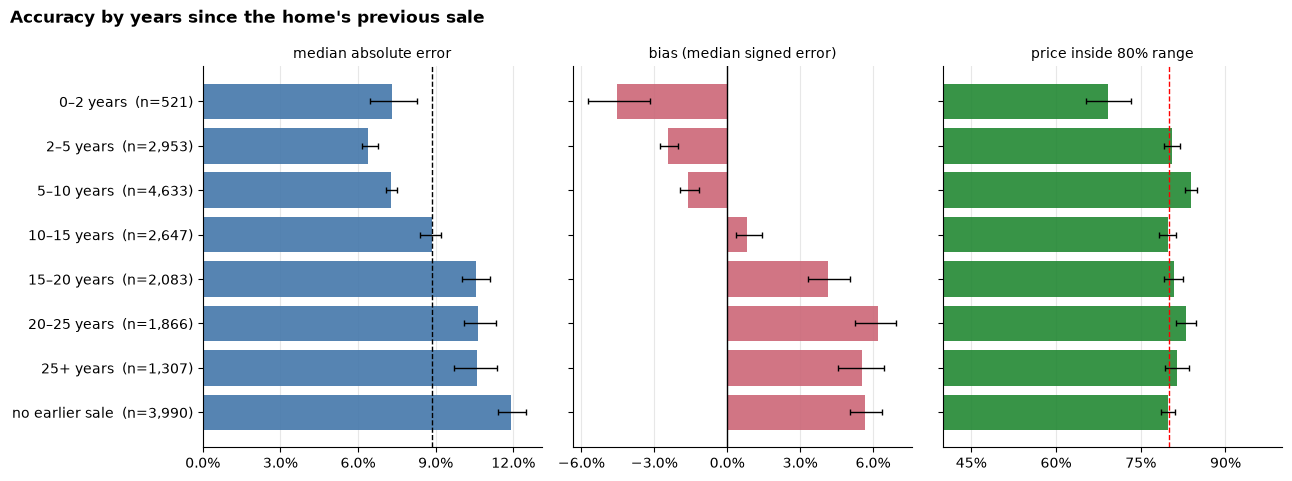

,n,median error,within ±10%,within ±20%,bias,in range
0–2 years,521,7.3%,58.7%,74.5%,-4.5%,69.3%
2–5 years,"2,953",6.4%,68.2%,89.0%,-2.4%,80.5%
5–10 years,"4,633",7.3%,62.9%,86.9%,-1.6%,83.9%
10–15 years,"2,647",8.9%,55.2%,83.2%,+0.8%,79.8%
15–20 years,"2,083",10.5%,47.8%,76.8%,+4.2%,80.8%
20–25 years,"1,866",10.6%,47.4%,75.3%,+6.2%,83.0%
25+ years,"1,307",10.6%,48.2%,74.0%,+5.5%,81.4%
no earlier sale,"3,990",11.9%,43.2%,69.2%,+5.7%,79.8%


In [14]:
bins = [0, 2, 5, 10, 15, 20, 25, 32]
names = [f"{a}–{b} years" for a, b in zip(bins[:-1], bins[1:-1])] + ["25+ years"]
eng["since"] = pd.cut(eng["years_since_last_sale"], bins, labels=names, right=False).astype(str)
eng.loc[eng["years_since_last_sale"].isna(), "since"] = "no earlier sale"
t_since = subset_plot(eng, "since", names + ["no earlier sale"], "Accuracy by years since the home's previous sale")

## 10. With and without EPC data

**Why this subset.** EPC data is optional, and it needs a separate manual download. EPCs supply floor area, which lets comparables be scaled to the target home's size. This matters most when there is no earlier sale. Both configurations were run on the same sales, and each used its own calibration.

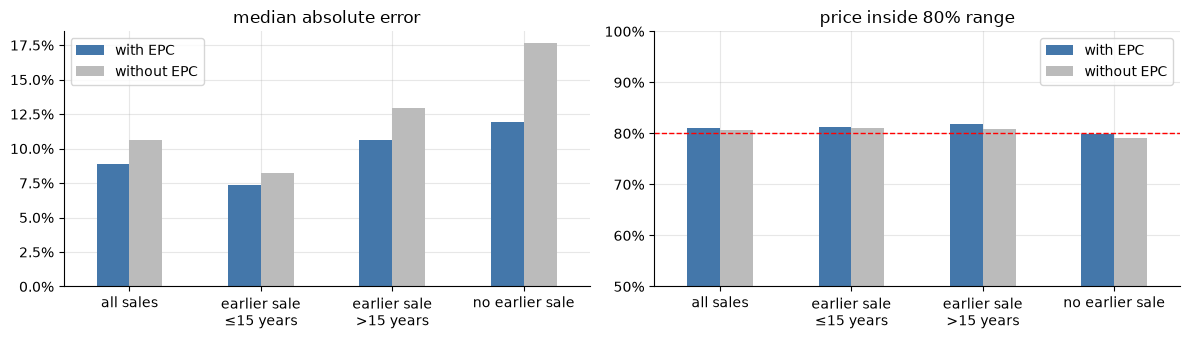

n median error within ±10%  \
subset                 config                                         
all sales              with EPC     20,000         8.9%       54.6%   
                       without EPC  20,000        10.7%       47.7%   
earlier sale >15 years with EPC      5,256        10.6%       47.8%   
                       without EPC   5,256        13.0%       39.9%   
earlier sale ≤15 years with EPC     10,754         7.3%       62.3%   
                       without EPC  10,754         8.3%       57.6%   
no earlier sale        with EPC      3,990        11.9%       43.2%   
                       without EPC   3,990        17.6%       31.3%   

                                   within ±20%   bias in range  
subset                 config                                   
all sales              with EPC          79.9%  +1.0%    81.1%  
                       without EPC       73.6%  +0.5%    80.6%  
earlier sale >15 years with EPC          75.6%  +5.2%    81.8%  
                       without EPC       68.6%  +5.2%    80.8%  
earlier sale ≤15 years with EPC          85.9%  -1.5%    81.2%  
                       without EPC       82.8%  -1.9%    81.0%  
no earlier sale        with EPC          69.2%  +5.7%    79.8%  
                       without EPC       55.3%  +4.7%    79.1%

In [15]:
eng["evidence"] = np.select(
    [eng["years_since_last_sale"] <= 15, eng["years_since_last_sale"] > 15],
    ["earlier sale ≤15 years", "earlier sale >15 years"], "no earlier sale")
rows = []
for name, g in [("all sales", eng)] + list(eng.groupby("evidence")):
    for prefix, cfg in [("", "with EPC"), ("noepc_", "without EPC")]:
        rows.append({"subset": name, "config": cfg, **stats(g, prefix)})
epc = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, col in enumerate(["median_error", "coverage"]):
    p = epc.pivot(index="subset", columns="config", values=col).reindex(
        ["all sales", "earlier sale ≤15 years", "earlier sale >15 years", "no earlier sale"])
    p.index = p.index.str.replace("sale ", "sale\n")
    p.columns.name = None
    p.plot.bar(ax=ax[i], rot=0, color=["#4477aa", "#bbbbbb"])
    ax[i].yaxis.set_major_formatter(PercentFormatter(1))
    ax[i].set(title=["median absolute error", "price inside 80% range"][i], xlabel="")
ax[1].axhline(0.8, ls="--", c="red", lw=1)
ax[1].set_ylim(0.5, 1)
fig.tight_layout()
plt.show()
display(table(epc.set_index(["subset", "config"])))

## 11. Norfolk and Suffolk

**Why this section.** Users of this pipeline are concentrated in Norfolk and Suffolk. These two counties together hold only about 2.5% of England's sales, too few in the England sample to break down. So we draw a **separate sample of sales from the two counties** over the same 12 months, valued the same way.

The two counties are largely rural, with one city each (Norwich, Ipswich). They include coastal and second-home markets in North Norfolk and East Suffolk, the Broads, Breckland's market towns, and fast-growing commuter fringes around Norwich and Ipswich. We check whether the England-wide accuracy and the England-wide calibration of the ranges hold here.

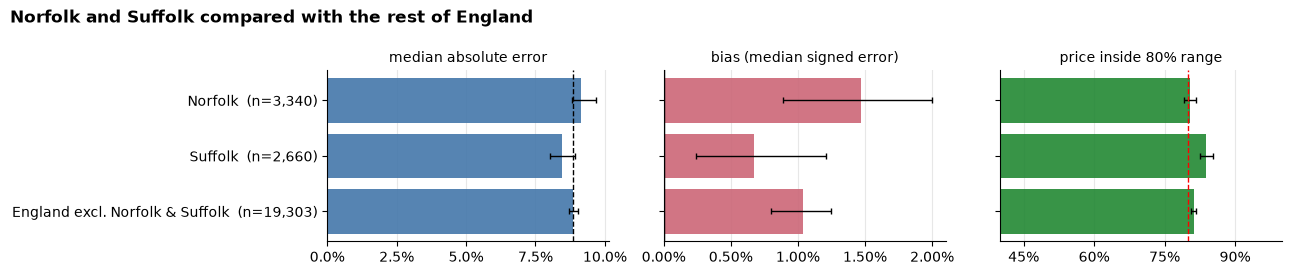

,n,median error,within ±10%,within ±20%,bias,in range
Norfolk,"3,340",9.1%,53.0%,79.1%,+1.5%,80.4%
Suffolk,"2,660",8.5%,56.3%,81.4%,+0.7%,83.9%
England excl. Norfolk & Suffolk,"19,303",8.9%,54.6%,79.9%,+1.0%,81.2%


In [16]:
rest = eng[~eng["cty"].isin([NORFOLK, SUFFOLK])].assign(county="England excl. Norfolk & Suffolk")
both = pd.concat([east, rest], ignore_index=True)
t_cty = subset_plot(both, "county", ["Norfolk", "Suffolk", "England excl. Norfolk & Suffolk"],
                    "Norfolk and Suffolk compared with the rest of England")

### By district

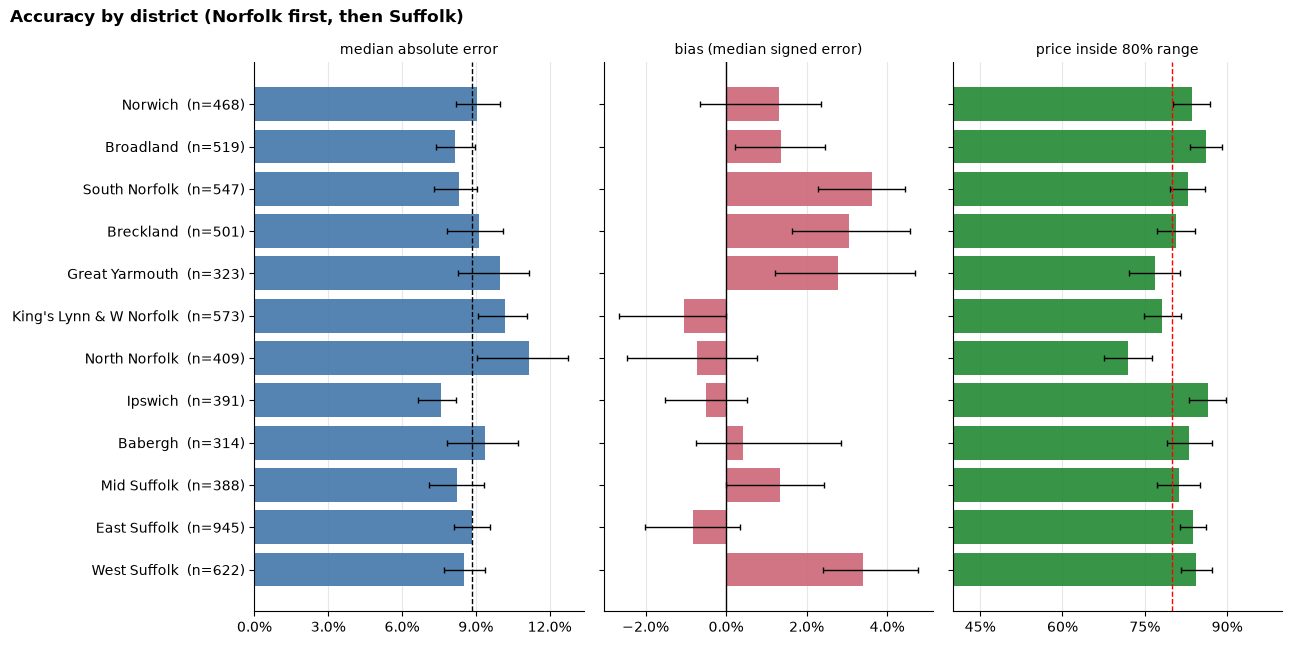

,n,median error,within ±10%,within ±20%,bias,in range
Norwich,468,9.1%,54.1%,81.8%,+1.3%,83.5%
Broadland,519,8.1%,59.0%,84.4%,+1.4%,86.1%
South Norfolk,547,8.3%,56.3%,81.4%,+3.6%,82.8%
Breckland,501,9.1%,53.3%,77.8%,+3.0%,80.6%
Great Yarmouth,323,10.0%,50.5%,76.2%,+2.8%,76.8%
King's Lynn & W Norfolk,573,10.2%,49.2%,79.2%,-1.1%,78.2%
North Norfolk,409,11.2%,46.9%,69.9%,-0.7%,71.9%
Ipswich,391,7.6%,62.9%,85.2%,-0.5%,86.4%
Babergh,314,9.4%,52.2%,80.3%,+0.4%,83.1%
Mid Suffolk,388,8.3%,57.5%,79.4%,+1.3%,81.2%


In [17]:
order = list(DISTRICTS.values())
t_dist = subset_plot(east, "district", order, "Accuracy by district (Norfolk first, then Suffolk)")

### Rural and urban within the two counties

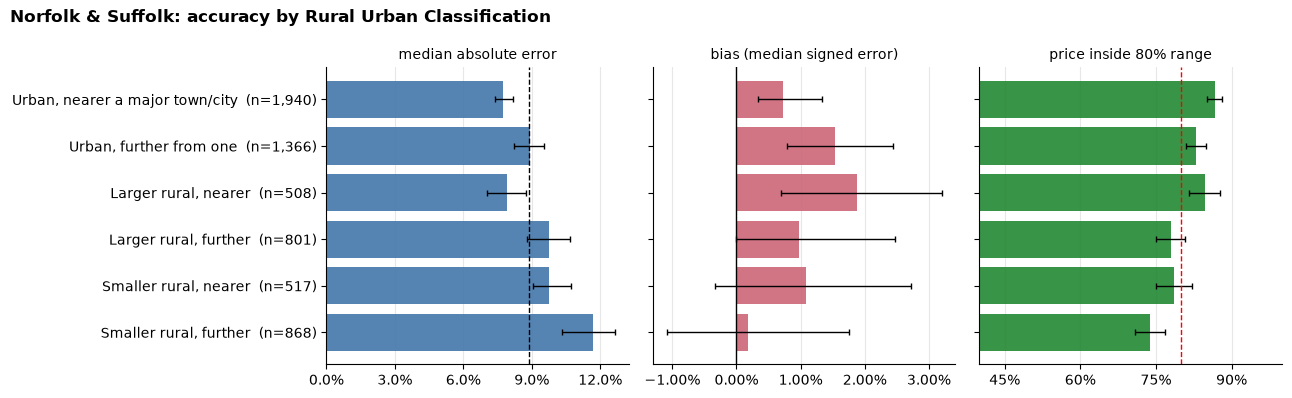

,n,median error,within ±10%,within ±20%,bias,in range
"Urban, nearer a major town/city","1,940",7.8%,59.9%,84.8%,+0.7%,86.6%
"Urban, further from one","1,366",8.9%,54.1%,82.8%,+1.5%,83.0%
"Larger rural, nearer",508,7.9%,59.8%,82.5%,+1.9%,84.6%
"Larger rural, further",801,9.8%,51.1%,77.5%,+1.0%,77.9%
"Smaller rural, nearer",517,9.7%,50.7%,74.1%,+1.1%,78.5%
"Smaller rural, further",868,11.7%,45.3%,70.2%,+0.2%,73.8%


Share of sales in rural areas: Norfolk & Suffolk 45%, rest of England 18%


In [18]:
t_east_ruc = subset_plot(east, "ruc", list(RUC.values()), "Norfolk & Suffolk: accuracy by Rural Urban Classification")
share = pd.DataFrame({"Norfolk & Suffolk": east["urban_rural"].value_counts(normalize=True),
                      "rest of England": rest["urban_rural"].value_counts(normalize=True)})
print("Share of sales in rural areas:", ", ".join(f"{k} {v:.0%}" for k, v in share.loc["Rural"].items()))

### Evidence, confidence and property type within the two counties

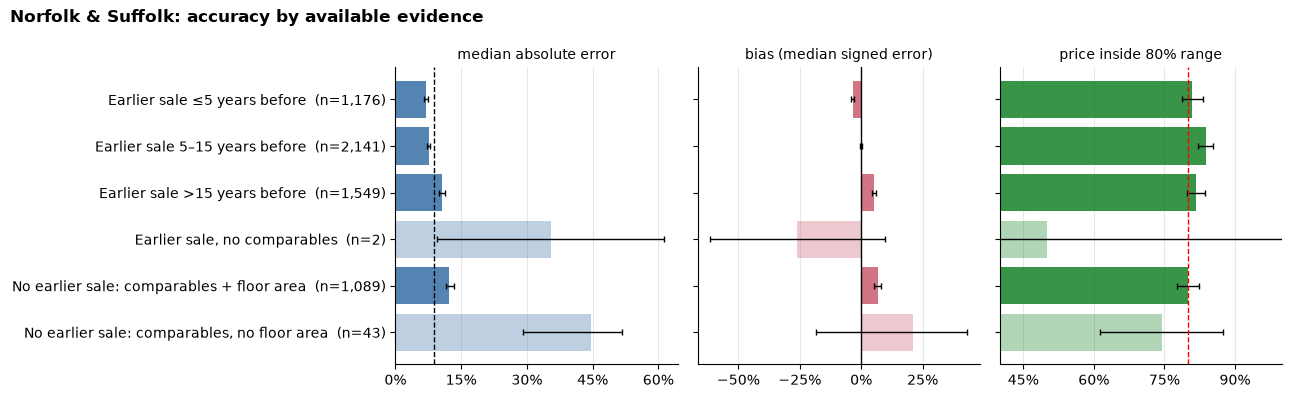

,n,median error,within ±10%,within ±20%,bias,in range
Earlier sale ≤5 years before,"1,176",7.0%,64.8%,88.1%,-3.4%,81.0%
Earlier sale 5–15 years before,"2,141",7.6%,61.2%,86.8%,+0.0%,83.8%
Earlier sale >15 years before,"1,549",10.7%,47.4%,75.5%,+5.3%,81.7%
"Earlier sale, no comparables",2,35.4%,50.0%,50.0%,-25.9%,50.0%
No earlier sale: comparables + floor area,"1,089",12.3%,42.0%,67.8%,+6.8%,80.1%
"No earlier sale: comparables, no floor area",43,44.7%,9.3%,14.0%,+21.2%,74.4%


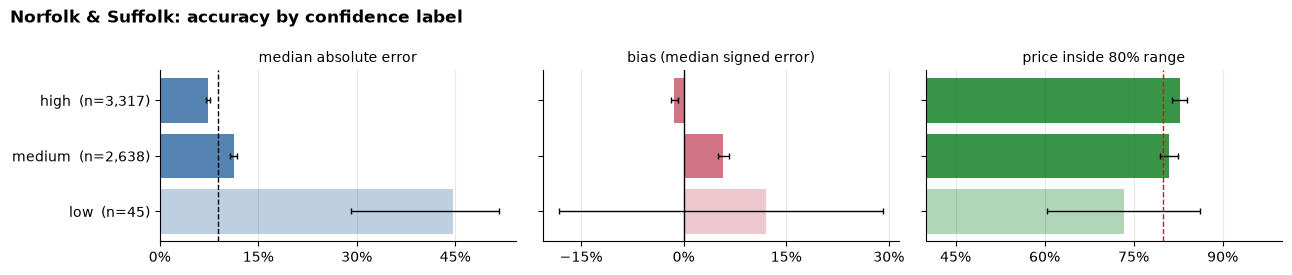

,n,median error,within ±10%,within ±20%,bias,in range
high,"3,317",7.3%,62.5%,87.2%,-1.4%,82.8%
medium,"2,638",11.3%,45.2%,72.3%,+5.7%,81.0%
low,45,44.7%,11.1%,15.6%,+12.0%,73.3%


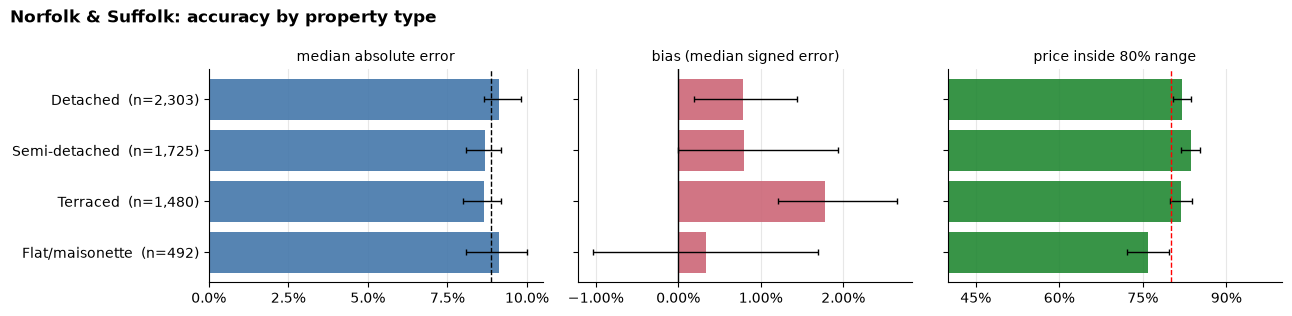

,n,median error,within ±10%,within ±20%,bias,in range
Detached,"2,303",9.1%,52.7%,79.5%,+0.8%,82.0%
Semi-detached,"1,725",8.7%,56.1%,81.6%,+0.8%,83.6%
Terraced,"1,480",8.6%,55.6%,79.9%,+1.8%,81.8%
Flat/maisonette,492,9.1%,53.7%,78.9%,+0.3%,76.0%


In [19]:
t_east_group = subset_plot(east, "group", list(GROUPS.values()), "Norfolk & Suffolk: accuracy by available evidence")
t_east_conf = subset_plot(east, "confidence", ["high", "medium", "low"], "Norfolk & Suffolk: accuracy by confidence label")
t_east_type = subset_plot(east, "type", list(TYPES.values()), "Norfolk & Suffolk: accuracy by property type")

## 12. Price bands instead of exact estimates

**Why this section.** By default, `estimate` does **not** output the exact estimate. It outputs a price band (`price_band`, e.g. `£250k–£275k`), with `low`/`high` widened outwards to band edges. Fields that pin down the location or sale history are also left out.

The reason is re-identification. The method is deterministic and uses only public data. Someone who knows roughly where the homes are could value every address in that area with this pipeline, then match precise outputs back to a single address. That would link your row, and anything joined to it such as participant data, to a home.

Band widths:

| estimate | band width |
|---|---|
| under £500k | £25k |
| £500k–£1m | £50k |
| £1m–£2m | £250k |
| £2m–£5m | £1m |
| over £5m | one open band, `£5m+` |

Pass `--keep-identifiable` to get exact values. This section measures what banding costs in accuracy and what it buys in privacy, using the same backtest sales. The banding below uses the same functions as the CLI.

In [20]:
from house_price_estimate.cli import price_band


def banded(df):
    """Add the default (banded) CLI outputs to backtest results."""
    df = df.dropna(subset=["estimate"]).copy()
    bands = df["estimate"].map(price_band)
    df["band_low"] = bands.str[0]
    df["band_high"] = bands.str[1]
    # The open top band has no midpoint; use its lower edge.
    df["band_mid"] = np.where(df["band_high"].isna(), df["band_low"], (df["band_low"] + df["band_high"]) / 2)
    df["b_low"] = df["low"].map(lambda x: price_band(x)[0])
    df["b_high"] = df["high"].map(lambda x: x if price_band(x)[0] == x else price_band(x)[1])
    return df


beng, beast = banded(eng), banded(east)


def compare(df, by=None, order=None):
    rows = []
    for k, g in ([("all", df)] if by is None else [(k, df[df[by] == k]) for k in order]):
        hi = g["b_high"].fillna(np.inf)
        rows.append({
            "subset": k, "n": len(g),
            "median error, exact estimate": (g["estimate"] / g["actual"] - 1).abs().median(),
            "median error, band midpoint": (g["band_mid"] / g["actual"] - 1).abs().median(),
            "in range, exact": ((g["actual"] >= g["low"]) & (g["actual"] <= g["high"])).mean(),
            "in range, banded": ((g["actual"] >= g["b_low"]) & (g["actual"] <= hi)).mean(),
            "range width, exact": ((g["high"] - g["low"]) / g["estimate"]).median(),
            "range width, banded": ((g["b_high"] - g["b_low"]) / g["estimate"]).median(),
            "sale price in the estimate's band": ((g["actual"] >= g["band_low"]) & (g["actual"] < g["band_high"].fillna(np.inf))).mean(),
        })
    out = pd.DataFrame(rows).set_index("subset")
    return out


def fmt(t):
    t = t.copy()
    for c in t.columns:
        t[c] = t[c].map("{:,}".format) if c == "n" else t[c].map("{:.1%}".format)
    return t


headline = pd.concat([compare(beng).rename(index={"all": "England"}),
                      compare(beast).rename(index={"all": "Norfolk & Suffolk"})])
display(fmt(headline))

,n,"median error, exact estimate","median error, band midpoint","in range, exact","in range, banded","range width, exact","range width, banded",sale price in the estimate's band
subset,,,,,,,,
England,"20,000",8.9%,9.4%,81.1%,88.1%,37.9%,48.9%,29.2%
Norfolk & Suffolk,"6,000",8.9%,9.4%,81.9%,88.4%,37.9%,48.5%,28.8%


### Accuracy: range coverage and the band as a point value

The banded range can only be wider than the exact one, so it covers more sale prices. That makes it more cautious, and less informative. The figure below shows coverage and width by confidence level and value band.

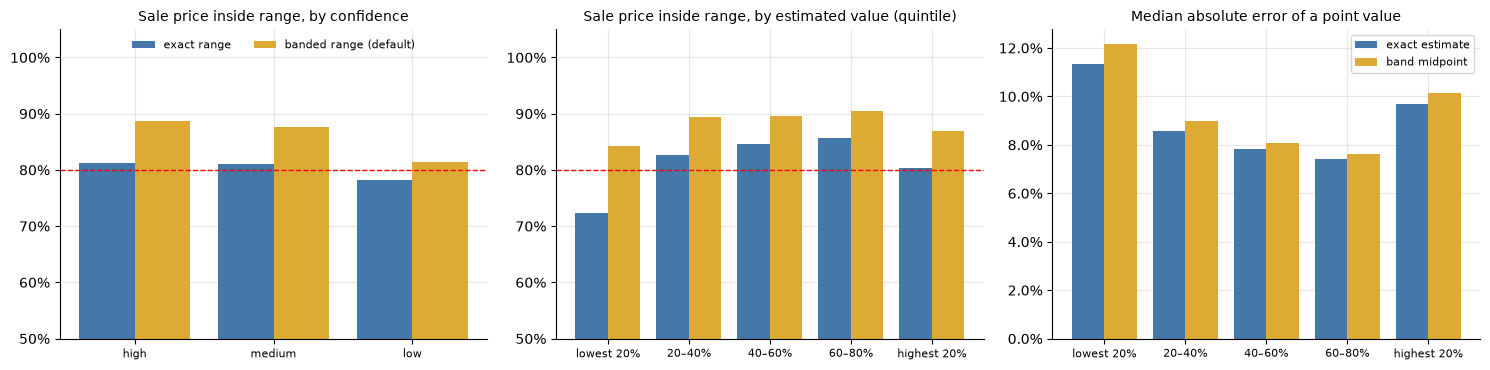

,n,"median error, exact estimate","median error, band midpoint","in range, exact","in range, banded","range width, banded"
subset,,,,,,
lowest 20%,"4,030",11.3%,12.2%,72.3%,84.2%,55.2%
20–40%,"3,989",8.6%,9.0%,82.6%,89.5%,49.5%
40–60%,"4,015",7.8%,8.1%,84.7%,89.7%,46.8%
60–80%,"3,973",7.4%,7.6%,85.7%,90.5%,47.3%
highest 20%,"3,993",9.7%,10.2%,80.3%,87.0%,48.2%


In [21]:
beng["value_band"] = pd.qcut(beng["estimate"], 5, labels=q_labels)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (by, order, title) in zip(ax, [("confidence", ["high", "medium", "low"], "by confidence"),
                                      ("value_band", q_labels, "by estimated value (quintile)")]):
    t = compare(beng, by, order)
    x = np.arange(len(t))
    a.bar(x - 0.2, t["in range, exact"], 0.4, label="exact range", color="#4477aa")
    a.bar(x + 0.2, t["in range, banded"], 0.4, label="banded range (default)", color="#ddaa33")
    a.set_xticks(x, t.index)
    a.axhline(0.8, ls="--", c="red", lw=1)
    a.set_ylim(0.5, 1.05)
    a.yaxis.set_major_formatter(PercentFormatter(1))
    a.set_title(f"Sale price inside range, {title}", fontsize=10)
ax[0].legend(fontsize=8, loc="upper center", ncol=2, frameon=False)
t = compare(beng, "value_band", q_labels)
x = np.arange(len(t))
ax[2].bar(x - 0.2, t["median error, exact estimate"], 0.4, label="exact estimate", color="#4477aa")
ax[2].bar(x + 0.2, t["median error, band midpoint"], 0.4, label="band midpoint", color="#ddaa33")
ax[2].set_xticks(x, t.index)
ax[2].yaxis.set_major_formatter(PercentFormatter(1))
ax[2].set_title("Median absolute error of a point value", fontsize=10)
ax[2].legend(fontsize=8)
for a in ax:
    a.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()
display(fmt(compare(beng, "value_band", q_labels)[["n", "median error, exact estimate", "median error, band midpoint",
                                                   "in range, exact", "in range, banded", "range width, banded"]]))

### Privacy: how distinctive is each output row?

For each sale in the Norfolk & Suffolk sample, we count how many sales in the sample produce *exactly the same output row*. We compare three versions of the output:
- the previous default, which included `comps_est` and the other comparables fields;
- the exact estimate and range, with the other identifying fields hidden;
- the current banded default.

A row shared by many sales is hard to link to one address. The sample is under 1% of the homes in the two counties, so a row shared by *k* sales in the sample is shared by very roughly 100 × *k* homes across the counties. These counts are illustrative. They are not a formal re-identification risk.

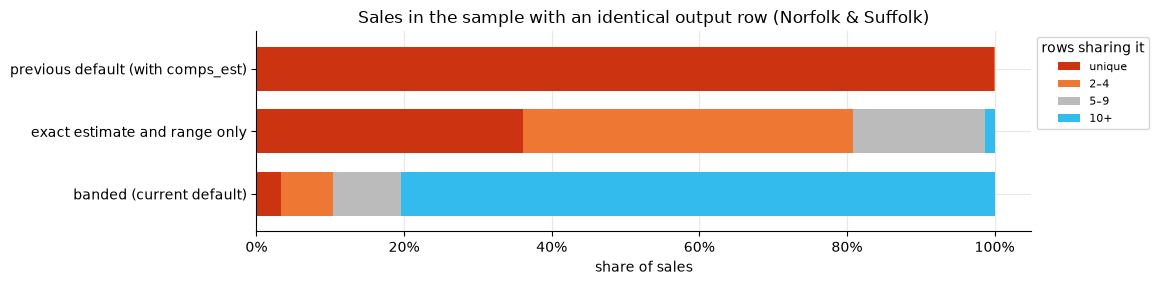

,unique,2–4,5–9,10+
previous default (with comps_est),100%,0%,0%,0%
exact estimate and range only,36%,45%,18%,1%
banded (current default),3%,7%,9%,80%


In [22]:
# valuation_month is left out: it is the same for every row of a real run,
# but varies with the sale date in this backtest.
common = ["status", "ppd_match", "epc_match", "property_type_source", "method", "calibration_group",
          "confidence"]
versions = {
    "previous default (with comps_est)": common + ["estimate", "low", "high", "comps_est", "comps_n", "comps_radius_m"],
    "exact estimate and range only": common + ["estimate", "low", "high"],
    "banded (current default)": common + ["band_low", "b_low", "b_high"],
}
cats = ["unique", "2–4", "5–9", "10+"]
dist = {}
for name, cols in versions.items():
    key = beast[cols].astype(str).agg("|".join, axis=1)
    k = key.map(key.value_counts())
    dist[name] = pd.cut(k, [0, 1, 4, 9, np.inf], labels=cats).value_counts(normalize=True).reindex(cats)
dist = pd.DataFrame(dist).T
fig, ax = plt.subplots(figsize=(10, 2.6))
dist.plot.barh(stacked=True, ax=ax, color=["#cc3311", "#ee7733", "#bbbbbb", "#33bbee"], width=0.7)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="share of sales", title="Sales in the sample with an identical output row (Norfolk & Suffolk)")
ax.legend(title="rows sharing it", fontsize=8, bbox_to_anchor=(1, 1), loc="upper left")
plt.show()
display(dist.map("{:.0%}".format))

### Advice for using banded output

- **The band is the estimate rounded, not a range for the price.** For example, an estimate of £262k becomes the band `£250k–£275k`. That does *not* mean the home will sell for between £250k and £275k. The typical error, about 9% or roughly £24k here, is about as large as the whole band. So only about 3 in 10 homes sell for a price within their estimate's band (column "sale price in the estimate's band" above). The rest sell in a neighbouring band or further away.
- **For the likely price range, use `low`–`high`.** In the default banded output, it contains the sale price about 85–90% of the time, a little more than the 80% it is designed for, because it is widened to band edges.
- **For a single number, use the band midpoint**, which the output gives as `price_band_mid`. Banding adds little error on top of the model's own error, as the figure above shows. The extra error is largest for the cheapest homes, where a £25k band is a large share of the price. For the open `£5m+` band, there is no midpoint, and `price_band_mid` is empty.
- **For statistical analysis:**
  - Use the midpoint, or its logarithm, as a continuous covariate. Or use the band as an ordered category.
  - The rounding error is roughly uniform within a band and much smaller than the valuation error, so it will rarely change conclusions. Remember the estimate itself is noisy, about ±9% typical error. As a covariate it carries measurement error, which biases regression slopes towards zero.
  - If house value is a main exposure, consider interval-censored or measurement-error methods.
- **Keep the default for anything shared.** Only use `--keep-identifiable` inside a secure environment. Treat its output as personal data, because exact estimates can be matched back to an address. Rarer combinations are still distinctive even when banded, for example a very high band, `postcode_mode` or `comps_no_floor_area`.
- **Don't add the location back.** Joining banded output to postcode, LSOA or small-area data, or publishing it alongside such data, undoes much of the protection. Aggregate before release, and suppress small cells.

## Summary

Figures are for the England sample of 20,000 sales (Aug 2025 to Jul 2026), with EPC data, unless stated otherwise.

**Overall.**
- The median error is **8.9%**. 55% of estimates are within ±10% of the sale price and 80% within ±20%.
- The `low`–`high` range contains the sale price **81%** of the time, matching its 80% design.
- There is almost no overall bias (+1.0%).

### Where the estimates can be trusted
- **The home has sold in the last 15 years** (54% of sales; `confidence = high`). The median error is 6.5–7.8%, and 86% are within ±20%. This is the core use case.
- **Typical houses in typical places.** Detached, semi-detached and terraced homes have about the same accuracy (8.5–8.6%). Southern and Midland regions are at 7.9–9.1%, and London does about as well as average (9.1%).
- **Norfolk and Suffolk overall.** Accuracy is the same as in the rest of England: Norfolk 9.1%, Suffolk 8.5%, England 8.9%. The ranges hold up locally too (80% and 84% coverage), even though 45% of sales in the two counties are rural, against 18% elsewhere. Ipswich (7.6%), Broadland and South Norfolk (8.1–8.3%) are the most accurate districts.

### Weaknesses
Each item gives the subset, its median error, and coverage of the 80% range.

1. **No sale history and no floor area** (about 1% of sales; `confidence = low`).
   - Median error is 33%, and in Norfolk & Suffolk 45%. Only a third are within ±20%.
   - Treat these as a rough guide only.
2. **No earlier sale** (20% of sales). Median error is 11.6%, and these homes tend to be **over-valued by about 6%**. They are valued from neighbours, which assumes an average home for the street.
3. **The earlier sale is more than 15 years old.**
   - Median error is about 10.6%, and estimates are over-valued by about 5%. Indexing an old price misses wear, and homes that change hands after a long ownership are often dated.
   - The opposite happens for **very recent resales (under 2 years)**: they are under-valued by 4.5%, and only 69% fall inside the range. These are often refurbish-and-resell homes, and the improvement is not in the data.
4. **Flats.**
   - Median error is 10.8%, and **coverage is only 74%**. Floor, outlook, lease length and service charge are not modelled.
   - The ranges are calibrated by evidence type, not property type, so for flats they are too narrow.
5. **Remote rural homes.**
   - In smaller rural settlements far from a major town, the median error is 11.8% and coverage is 72%. In Norfolk & Suffolk the figures are 11.7% and 74%.
   - Only about half of these homes have comparables within 500 m.
   - Rural is harder *even with the same evidence*. For example, with no earlier sale the error is 13.8% in rural areas against 11.2% in urban areas. So the problem is not just less data.
6. **North of England and the cheapest homes.**
   - In the North East, North West and Yorkshire & Humber, the median error is about 10% and coverage 76–78%.
   - Homes estimated under about £190k have a median error of 11.3% and coverage of only 72%. A fixed cost such as condition or a short lease is a larger share of a low price.
7. **North Norfolk, King's Lynn & West Norfolk and Great Yarmouth.**
   - These are the weakest local districts. Errors are 10–11%, and North Norfolk's coverage is 72%. Coastal, second-home and holiday markets vary a lot from house to house.
   - South Norfolk, Breckland and West Suffolk are over-valued by about 3%.
8. **Uncertain address matches.**
   - A `fuzzy` match has a median error of 11.6% and coverage of 69%. Check the result if accuracy matters.
   - A wrong property type is rare (under 3% of sales) but costly. When the type was guessed from the postcode, the error is 29–46%.

### Practical advice
- **Use the range, not just the point estimate.** Expect about one sale in five to fall outside it. For flats, remote rural homes, homes under about £200k, and North Norfolk, widen it mentally, because coverage there is 70–75%.
- **Filter or flag on `confidence`.** `high` means about 7% typical error. `medium` means about 11%, and those homes are typically over-valued by about 5%. `low` is indicative only.
- **Check `ppd_match` and `property_type_source`.** A `fuzzy` match, or a type taken from `postcode_mode`, deserves a manual look.
- **Load the EPC data.** It cuts the median error from 10.7% to 8.9% overall, and from 17.6% to 11.9% for homes with no earlier sale.
- **Default output is banded (section 12).** This costs little accuracy: using the band midpoint instead of the exact estimate takes the median error from 8.9% to 9.4%. The banded range covers about 88% of sale prices, against 81% for the exact range. In return, 80% of Norfolk & Suffolk rows share their output with at least 10 sampled sales, against 1% when exact estimates are given. Use `--keep-identifiable` only in a secure environment.
- **Results are statistical.** They do not replace a survey for an individual home. Condition, extensions and plot are invisible to the model.